# 02. Экспертные признаки, статистический анализ и baseline

**Цель этапа:** выяснить, насколько хорошо задача решается классическими методами — экспертными
признаками и «неглубокими» моделями, — и получить **baseline**, с которым будут сравниваться нейросети.

**Шаги:**
1. Признаки (`src/amc/features.py`, 26 штук) и их распределения.
2. Статистический отбор признаков: критерий Краскела–Уоллиса + размер эффекта, корреляции Спирмена.
3. Апостериорный критерий Данна для трудных пар классов.
4. Лестница baseline (5-fold CV): угадывание → дерево по кумулянтам → логистическая регрессия →
   случайный лес → LightGBM.
5. Подбор гиперпараметров LightGBM (Optuna) и проверка отбора признаков.
6. Оценка на тесте: accuracy(ОСШ), матрицы ошибок, доверительные интервалы, критерий Мак-Немара.
7. Интерпретация: SHAP.
8. Выводы.

Датасеты: **RadioML 2016.10a** (128 отсчётов) и **свой** `synth/v1` (1024 отсчёта; для сравнения с RadioML —
также первые 128 отсчётов). Разбиение train/val/test — фиксированное (`amc.data`), тест используется только
в п. 6.

In [1]:
import os
import time
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import scikit_posthocs as sp
import seaborn as sns
import shap
from scipy.stats import kruskal
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from statsmodels.stats.contingency_tables import mcnemar

from amc.evaluate import acc_by_snr, bootstrap_ci, summary
from amc.features import FEATURES
from amc.generator import CLASSES

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures" / "baseline"
FIG.mkdir(parents=True, exist_ok=True)
OUT = ROOT / "models" / "baseline"
OUT.mkdir(parents=True, exist_ok=True)
JOBS = max(1, (os.cpu_count() or 2) - max(1, (os.cpu_count() or 2) // 4))
SEED = 42
sns.set_theme(style="whitegrid")
optuna.logging.set_verbosity(optuna.logging.WARNING)


def savefig(name: str) -> None:
    """Сохранить рисунок."""
    plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight")


DS = {name: pd.read_parquet(ROOT / "data" / "features" / f"{name}.parquet")
      for name in ["rml2016a", "synth_v1", "synth_v1_128"]}
for k, d in DS.items():
    bad = ~np.isfinite(d[FEATURES].to_numpy()).all(axis=1)
    print(f"{k}: {d.shape}, строк с NaN/inf: {bad.sum()}", d["split"].value_counts().to_dict())

<site-packages>\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


rml2016a: (220000, 30), строк с NaN/inf: 0 {'train': 132000, 'test': 44000, 'val': 44000}
synth_v1: (220000, 30), строк с NaN/inf: 0 {'train': 131998, 'val': 44004, 'test': 43998}
synth_v1_128: (220000, 30), строк с NaN/inf: 0 {'train': 131998, 'val': 44004, 'test': 43998}


## 1. Распределения признаков (ОСШ ≥ 10 дБ)

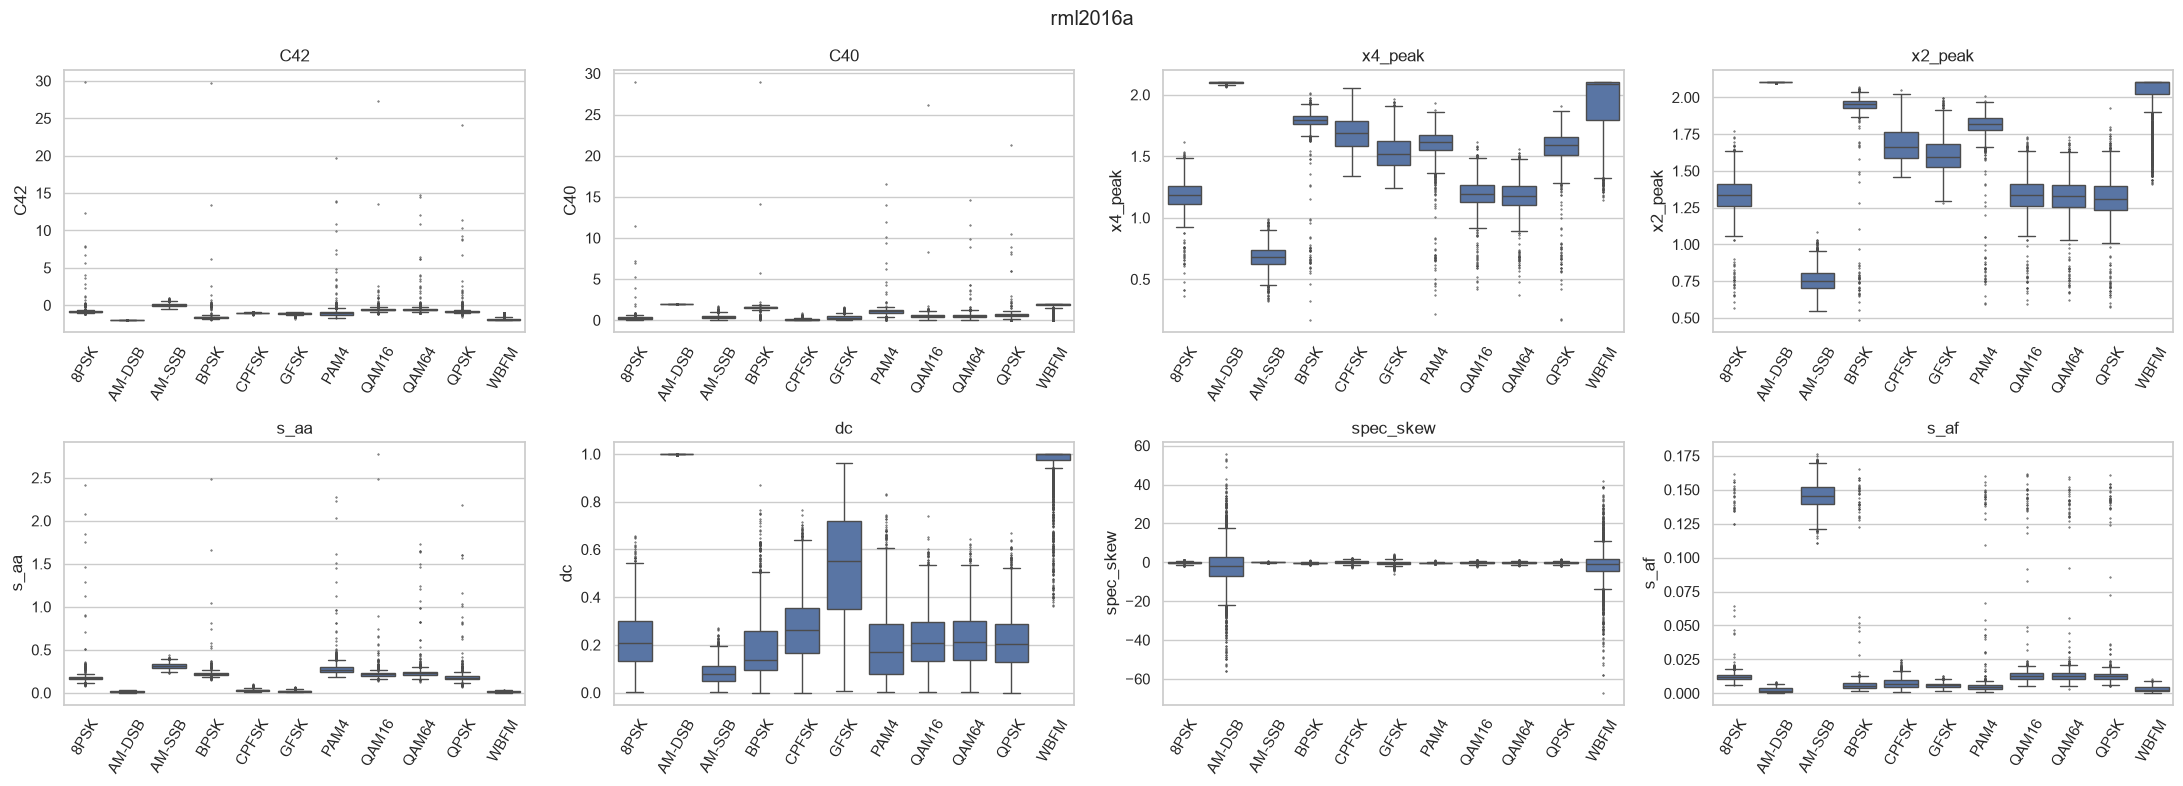

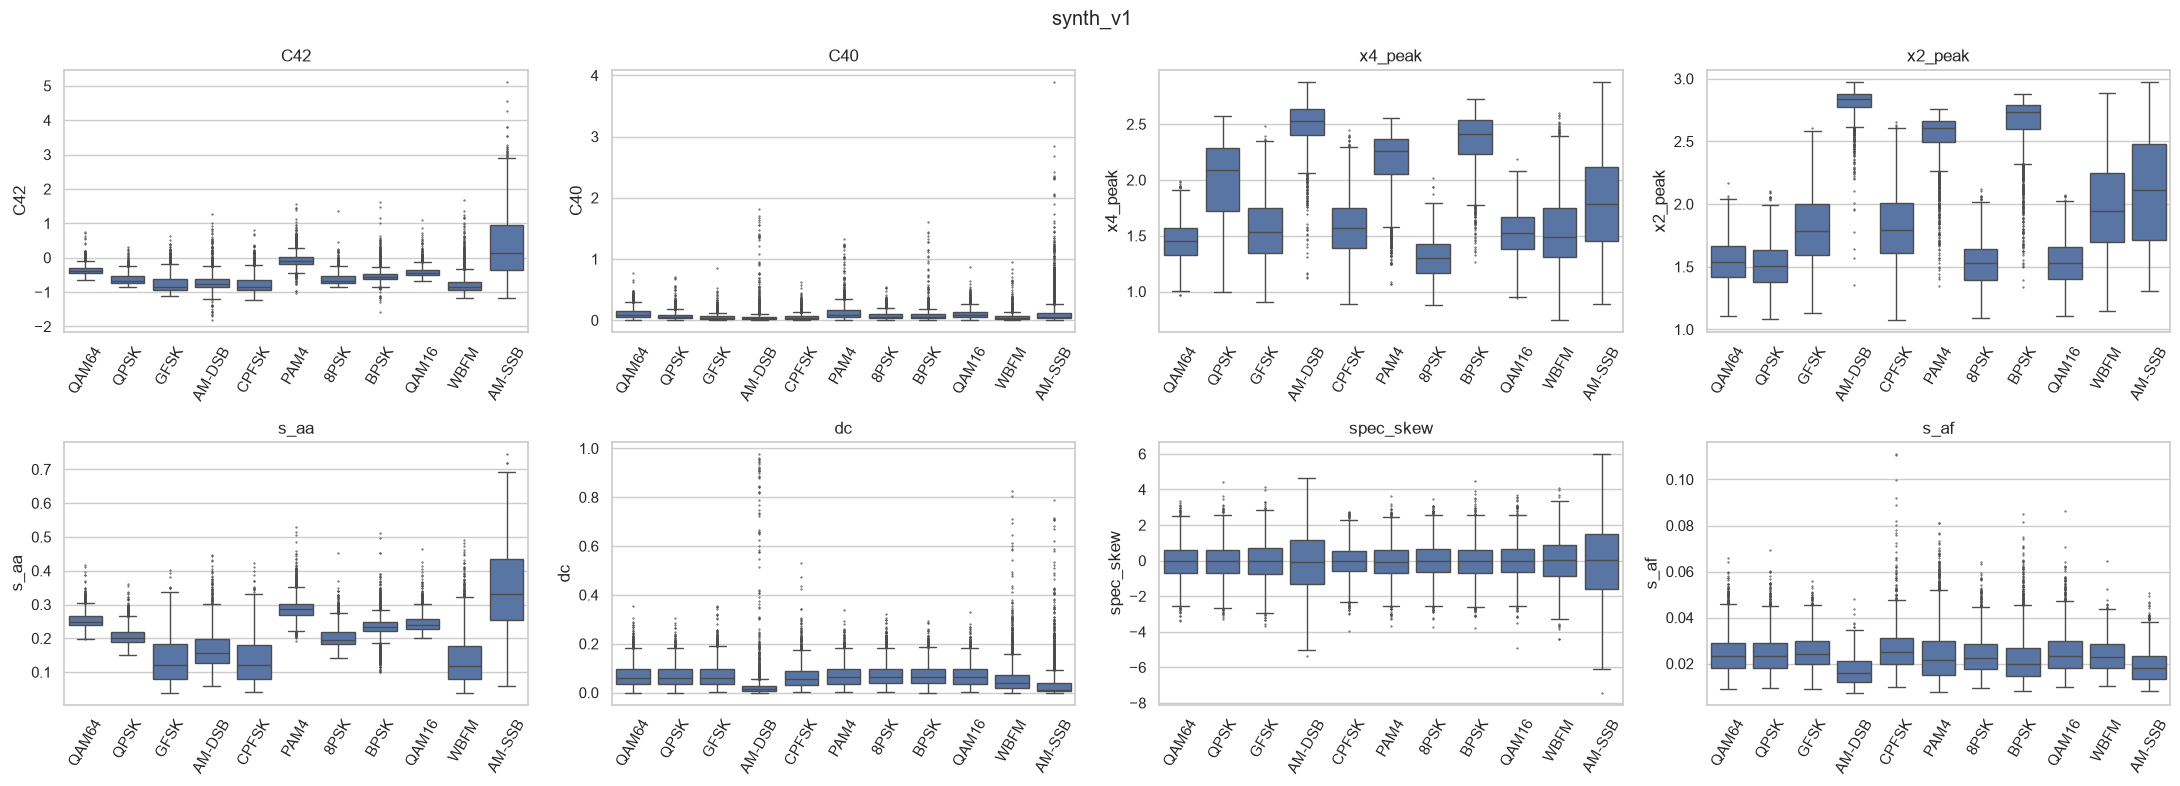

In [2]:
show = ["C42", "C40", "x4_peak", "x2_peak", "s_aa", "dc", "spec_skew", "s_af"]
for name in ["rml2016a", "synth_v1"]:
    d = DS[name]
    d = d[(d.snr_db >= 10) & (d.split == "train")]
    fig, axes = plt.subplots(2, 4, figsize=(22, 8))
    for ax, f in zip(axes.ravel(), show):
        sns.boxplot(data=d, x="cls", y=f, ax=ax, fliersize=0.5)
        ax.tick_params(axis="x", rotation=60)
        ax.set_xlabel("")
        ax.set_title(f)
    fig.suptitle(name)
    plt.tight_layout()
    savefig(f"feat_box_{name}")
    plt.show()

Признаки ведут себя по теории: C42 ≈ −2 у BPSK, ≈ −1 у QPSK/8PSK, ≈ −0,6…−0,7 у QAM; линия z⁴ есть у
BPSK/QPSK/PAM4/QAM и нет у 8PSK; постоянная составляющая (`dc`) выделяет AM-DSB (несущая);
асимметрия спектра выделяет AM-SSB в своём датасете. В RadioML у AM-SSB признаки — как у шума.

## 2. Статистический отбор признаков

**Критерий Краскела–Уоллиса** (непараметрический аналог однофакторного дисперсионного анализа): различаются
ли распределения признака между 11 классами. Выбран вместо ANOVA, т.к. распределения признаков
не нормальные и с разной дисперсией (видно на рисунках выше).

При десятках тысяч примеров почти любое различие «значимо» (p ≈ 0), поэтому решение принимается по
**размеру эффекта** ε² = H / (n − 1) (доля «объяснённой» рангами вариации):
ε² ≥ 0,26 — сильный, 0,08–0,26 — средний, 0,01–0,08 — слабый эффект.
Считается на train при ОСШ ≥ 0 дБ (при более низком ОСШ все классы похожи на шум).

**Правило отбора:** оставить признаки с ε² ≥ 0,08 (хотя бы средний эффект) в одном из датасетов,
затем из пар с |ρ Спирмена| > 0,95 удалить признак с меньшим ε².

In [3]:
def kw_table(d: pd.DataFrame) -> pd.DataFrame:
    """Краскел–Уоллис по каждому признаку между классами."""
    rows = []
    for f in FEATURES:
        groups = [g[f].to_numpy() for _, g in d.groupby("label")]
        h, p = kruskal(*groups)
        rows.append({"признак": f, "H": h, "p": p, "eps2": h / (len(d) - 1)})
    return pd.DataFrame(rows).set_index("признак")


kw = {}
for name in ["rml2016a", "synth_v1"]:
    d = DS[name]
    kw[name] = kw_table(d[(d.split == "train") & (d.snr_db >= 0)])
kw_all = pd.concat({k: v["eps2"] for k, v in kw.items()}, axis=1).sort_values("synth_v1", ascending=False)
kw_all["max"] = kw_all.max(axis=1)
print("максимальное p-значение:", max(v["p"].max() for v in kw.values()))
kw_all.round(3)

максимальное p-значение: 0.009860467


,rml2016a,synth_v1,max
признак,,,
x2_peak,0.833,0.648,0.833
peak_frac,0.725,0.493,0.725
s_aa,0.790,0.416,0.790
C42,0.818,0.412,0.818
C63,0.819,0.393,0.819
gmax,0.845,0.354,0.845
x4_peak,0.594,0.337,0.594
env_peak,0.391,0.273,0.391
kurt_f,0.761,0.264,0.761


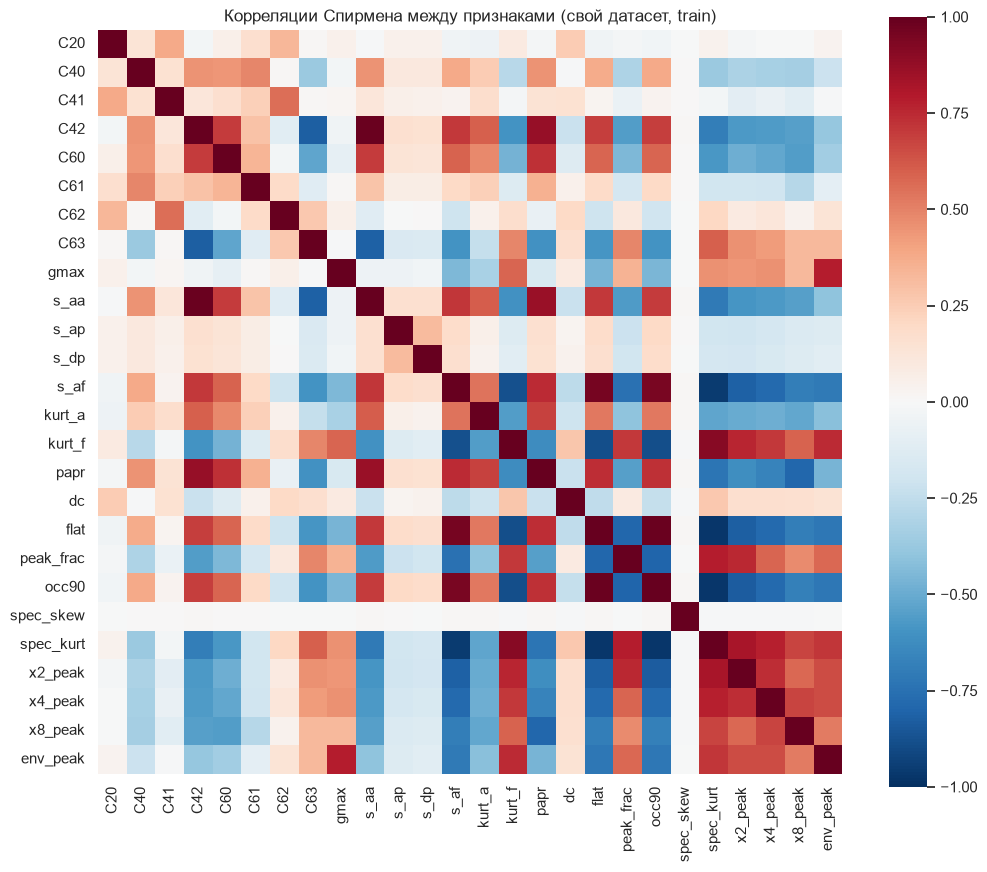

отобрано 21 из 26: ['x2_peak', 'peak_frac', 'C42', 'C63', 'gmax', 'x4_peak', 'env_peak', 'kurt_f', 'papr', 'C60', 'dc', 's_dp', 's_ap', 'kurt_a', 'C20', 'C40', 'C62', 'C41', 'occ90', 'x8_peak', 'C61']
исключены (слабый эффект): ['spec_skew']
исключены (дублируют более сильный признак, |ρ| > 0,95): ['s_af', 'flat', 'spec_kurt', 's_aa']


In [4]:
d = DS["synth_v1"]
rho = d[d.split == "train"][FEATURES].corr(method="spearman")
plt.figure(figsize=(12, 10))
sns.heatmap(rho, cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Корреляции Спирмена между признаками (свой датасет, train)")
savefig("spearman")
plt.show()

selected = [f for f in kw_all.index if kw_all.loc[f, "max"] >= 0.08]
dropped_weak = [f for f in FEATURES if f not in selected]
dropped_corr = []
for f in sorted(selected, key=lambda f: kw_all.loc[f, "max"]):
    partners = [g for g in selected if g != f and g not in dropped_corr and abs(rho.loc[f, g]) > 0.95]
    if partners and all(kw_all.loc[g, "max"] >= kw_all.loc[f, "max"] for g in partners):
        dropped_corr.append(f)
selected = [f for f in selected if f not in dropped_corr]
print(f"отобрано {len(selected)} из {len(FEATURES)}: {selected}")
print("исключены (слабый эффект):", dropped_weak)
print("исключены (дублируют более сильный признак, |ρ| > 0,95):", dropped_corr)

## 3. Трудные пары классов: критерий Данна

Краскел–Уоллис говорит, что классы различаются «в целом». Для пар, которые ожидаемо путаются
(QAM16/QAM64, QPSK/8PSK, AM-DSB/WBFM), нужен **апостериорный критерий Данна** с поправкой Холма
на множественные сравнения. Подвыборка — по 2000 примеров класса при ОСШ ≥ 10 дБ (train).
Помимо p-значения — разность медиан в единицах межквартильного размаха (практическая величина различия).

In [5]:
pairs = [("QAM16", "QAM64"), ("QPSK", "8PSK"), ("AM-DSB", "WBFM")]
rng = np.random.default_rng(SEED)
dunn_rows = []
for name in ["rml2016a", "synth_v1"]:
    d = DS[name]
    d = d[(d.split == "train") & (d.snr_db >= 10)]
    for a, b in pairs:
        sub = pd.concat([g.sample(2000, random_state=SEED) for c, g in d.groupby("cls") if c in (a, b)])
        for f in selected:
            p = sp.posthoc_dunn(sub, val_col=f, group_col="cls", p_adjust="holm").loc[a, b]
            iqr = sub[f].quantile(0.75) - sub[f].quantile(0.25) + 1e-12
            eff = abs(sub.loc[sub.cls == a, f].median() - sub.loc[sub.cls == b, f].median()) / iqr
            dunn_rows.append({"датасет": name, "пара": f"{a}/{b}", "признак": f, "p_holm": p, "эффект": eff})
dunn = pd.DataFrame(dunn_rows)
best_pairs = (dunn[dunn.p_holm < 0.05].sort_values("эффект", ascending=False)
              .groupby(["датасет", "пара"]).head(3))
best_pairs.round(4)

,датасет,пара,признак,p_holm,эффект
110,synth_v1,AM-DSB/WBFM,x4_peak,0.0000,0.9978
105,synth_v1,AM-DSB/WBFM,x2_peak,0.0000,0.9955
26,rml2016a,QPSK/8PSK,x4_peak,0.0000,0.9874
123,synth_v1,AM-DSB/WBFM,occ90,0.0000,0.9783
89,synth_v1,QPSK/8PSK,x4_peak,0.0000,0.9764
36,rml2016a,QPSK/8PSK,C40,0.0000,0.9476
41,rml2016a,QPSK/8PSK,C61,0.0000,0.8141
56,rml2016a,AM-DSB/WBFM,C20,0.0000,0.7080
53,rml2016a,AM-DSB/WBFM,s_dp,0.0000,0.6960
54,rml2016a,AM-DSB/WBFM,s_ap,0.0000,0.6916


## 4. Лестница baseline (5-fold CV на train)

| Ступень | Модель | Смысл |
|---|---|---|
| 0 | самый частый класс | нижняя граница (1/11 ≈ 9 %) |
| 1 | дерево глубины 4 только по кумулянтам | классический «экспертный» классификатор-правила |
| 2 | логистическая регрессия на всех признаках | линейная модель |
| 3 | случайный лес | нелинейный ансамбль |
| 4 | LightGBM | градиентный бустинг |

In [6]:
CUM = ["C20", "C40", "C41", "C42", "C60", "C61", "C62", "C63"]
ladder = {
    "0 самый частый": (DummyClassifier(strategy="most_frequent"), FEATURES),
    "1 дерево (кумулянты)": (DecisionTreeClassifier(max_depth=4, random_state=SEED), CUM),
    "2 логрегрессия": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), FEATURES),
    "3 случайный лес": (RandomForestClassifier(n_estimators=150, min_samples_leaf=3, n_jobs=JOBS,
                                                random_state=SEED), FEATURES),
    "4 LightGBM": (lgb.LGBMClassifier(n_estimators=400, learning_rate=0.1, num_leaves=63, n_jobs=JOBS,
                                      random_state=SEED, verbose=-1), FEATURES),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
cv_rows = []
for name in ["rml2016a", "synth_v1"]:
    d = DS[name]
    tr = d[d.split == "train"]
    for mname, (model, feats) in ladder.items():
        t0 = time.time()
        s = cross_val_score(model, tr[feats], tr["label"], cv=cv, scoring="accuracy", n_jobs=1)
        cv_rows.append({"датасет": name, "модель": mname, "CV acc": s.mean(), "± СКО": s.std(),
                        "время, с": time.time() - t0})
        print(name, mname, f"{s.mean():.4f} ± {s.std():.4f}", flush=True)
cv_table = pd.DataFrame(cv_rows).pivot(index="модель", columns="датасет", values=["CV acc", "± СКО"])
cv_table.round(4)

rml2016a 0 самый частый 0.0909 ± 0.0000


rml2016a 1 дерево (кумулянты) 0.3609 ± 0.0020


rml2016a 2 логрегрессия 0.5077 ± 0.0017


rml2016a 3 случайный лес 0.5407 ± 0.0017


rml2016a 4 LightGBM 0.5339 ± 0.0013


synth_v1 0 самый частый 0.0909 ± 0.0000


synth_v1 1 дерево (кумулянты) 0.1765 ± 0.0011


synth_v1 2 логрегрессия 0.4617 ± 0.0021


synth_v1 3 случайный лес 0.5071 ± 0.0024


synth_v1 4 LightGBM 0.5094 ± 0.0022


CV acc             ± СКО         
датасет              rml2016a synth_v1 rml2016a synth_v1
модель                                                  
0 самый частый         0.0909   0.0909   0.0000   0.0000
1 дерево (кумулянты)   0.3609   0.1765   0.0020   0.0011
2 логрегрессия         0.5077   0.4617   0.0017   0.0021
3 случайный лес        0.5407   0.5071   0.0017   0.0024
4 LightGBM             0.5339   0.5094   0.0013   0.0022

## 5. Подбор гиперпараметров LightGBM (Optuna) и проверка отбора признаков

Подбор — по **val** (не по тесту), байесовская оптимизация (TPE), 20 попыток, ранняя остановка
по логистической потере на val. Для скорости каждая попытка обучается на случайных 50 тыс. примеров train;
финальная модель — на всём train с теми же параметрами и ранней остановкой по val.
Затем — сравнение «все признаки» против «отобранные» на val.

In [7]:
def tune_lgbm(d: pd.DataFrame, feats: list[str], n_trials: int = 20) -> tuple[dict, float]:
    """Подбор гиперпараметров LightGBM на val; возвращает лучшие параметры и accuracy на val."""
    tr = d[d.split == "train"].sample(50000, random_state=SEED)
    va = d[d.split == "val"]

    def objective(trial: optuna.Trial) -> float:
        params = dict(
            n_estimators=2000, learning_rate=trial.suggest_float("learning_rate", 0.05, 0.3, log=True),
            num_leaves=trial.suggest_int("num_leaves", 15, 255, log=True),
            min_child_samples=trial.suggest_int("min_child_samples", 5, 200, log=True),
            subsample=trial.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
            reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
            n_jobs=JOBS, random_state=SEED, verbose=-1)
        m = lgb.LGBMClassifier(**params)
        m.fit(tr[feats], tr["label"], eval_set=[(va[feats], va["label"])],
              callbacks=[lgb.early_stopping(50, verbose=False)])
        return (m.predict(va[feats]) == va["label"]).mean()

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials)
    best = dict(study.best_params, n_estimators=3000, subsample_freq=1, n_jobs=JOBS, random_state=SEED,
                verbose=-1)
    return best, study.best_value


tuned = {}
for name in ["rml2016a", "synth_v1"]:
    for fs_name, feats in [("все", FEATURES), ("отобранные", selected)]:
        t0 = time.time()
        params, acc = tune_lgbm(DS[name], feats)
        tuned[(name, fs_name)] = (params, acc)
        print(f"{name}, признаки: {fs_name}: val acc {acc:.4f} ({time.time() - t0:.0f} с)", params, flush=True)

<site-packages>\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


<site-packages>\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


<site-packages>\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


<site-packages>\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


<site-packages>\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


<site-packages>\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


... (74 outputs left out)

<site-packages>\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


<site-packages>\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


<site-packages>\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


synth_v1, признаки: отобранные: val acc 0.4918 (129 с) {'learning_rate': 0.05562230591377375, 'num_leaves': 48, 'min_child_samples': 75, 'subsample': 0.7720830293430568, 'colsample_bytree': 0.44302731752331276, 'reg_lambda': 6.4190666845149815, 'n_estimators': 3000, 'subsample_freq': 1, 'n_jobs': 18, 'random_state': 42, 'verbose': -1}


## 6. Оценка на тесте
Модели обучаются на train (LightGBM — с подобранными параметрами и тем набором признаков, что лучше на val)
и один раз оцениваются на test.

In [8]:
results, preds = [], {}
for name in ["rml2016a", "synth_v1", "synth_v1_128"]:
    d = DS[name]
    tr, te = d[d.split == "train"], d[d.split == "test"]
    base = name.replace("_128", "")
    fs_best = max(["все", "отобранные"], key=lambda k: tuned[(base, k)][1])
    feats_best = FEATURES if fs_best == "все" else selected
    models = {k: v for k, v in ladder.items() if k != "4 LightGBM"}
    models["5 LightGBM (Optuna)"] = (lgb.LGBMClassifier(**tuned[(base, fs_best)][0]), feats_best)
    va = d[d.split == "val"]
    for mname, (model, feats) in models.items():
        if mname.startswith("5"):
            model.fit(tr[feats], tr["label"], eval_set=[(va[feats], va["label"])],
                      callbacks=[lgb.early_stopping(50, verbose=False)])
        else:
            model.fit(tr[feats], tr["label"])
        p = model.predict(te[feats])
        preds[(name, mname)] = p
        results.append({"датасет": name, "модель": mname, **summary(te["label"], p, te["snr_db"].to_numpy(),
                                                                     CLASSES)})
        if mname.startswith("5"):
            proba = model.predict_proba(d[feats])
            np.savez(OUT / f"{name}_lgbm.npz", proba=proba.astype(np.float32), split=d["split"].to_numpy(),
                     label=d["label"].to_numpy())
            # LightGBM (C API) не открывает пути с кириллицей на Windows → запись через Python
            (OUT / f"{name}_lgbm.txt").write_text(model.booster_.model_to_string(), encoding="utf-8")
res = pd.DataFrame(results).set_index(["датасет", "модель"])
res.round(4)

<site-packages>\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


<site-packages>\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


<site-packages>\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


acc  acc_snr>=0  acc_snr>=10  macro_f1  \
датасет      модель                                                            
rml2016a     0 самый частый        0.0909      0.0909       0.0909    0.0152   
             1 дерево (кумулянты)  0.3608      0.5704       0.6605    0.3382   
             2 логрегрессия        0.5103      0.7804       0.8054    0.5179   
             3 случайный лес       0.5445      0.8347       0.8573    0.5649   
             5 LightGBM (Optuna)   0.5477      0.8372       0.8586    0.5665   
synth_v1     0 самый частый        0.0909      0.0909       0.0893    0.0151   
             1 дерево (кумулянты)  0.1776      0.2603       0.3142    0.1145   
             2 логрегрессия        0.4587      0.6861       0.7300    0.4567   
             3 случайный лес       0.5076      0.7395       0.8041    0.5075   
             5 LightGBM (Optuna)   0.5145      0.7526       0.8227    0.5140   
synth_v1_128 0 самый частый        0.0909      0.0909       0.0893    0.0151   
             1 дерево (кумулянты)  0.1566      0.2205       0.2765    0.1042   
             2 логрегрессия        0.3176      0.4977       0.5721    0.3108   
             3 случайный лес       0.3482      0.5441       0.6300    0.3457   
             5 LightGBM (Optuna)   0.3522      0.5530       0.6450    0.3477   

                                   acc_без_AM-SSB  
датасет      модель                                
rml2016a     0 самый частый                0.1000  
             1 дерево (кумулянты)          0.2993  
             2 логрегрессия                0.4816  
             3 случайный лес               0.5050  
             5 LightGBM (Optuna)           0.5092  
synth_v1     0 самый частый                0.1000  
             1 дерево (кумулянты)          0.1713  
             2 логрегрессия                0.4428  
             3 случайный лес               0.4944  
             5 LightGBM (Optuna)           0.5010  
synth_v1_128 0 самый частый                0.1000  
             1 дерево (кумулянты)          0.1711  
             2 логрегрессия                0.3160  
             3 случайный лес               0.3395  
             5 LightGBM (Optuna)           0.3420

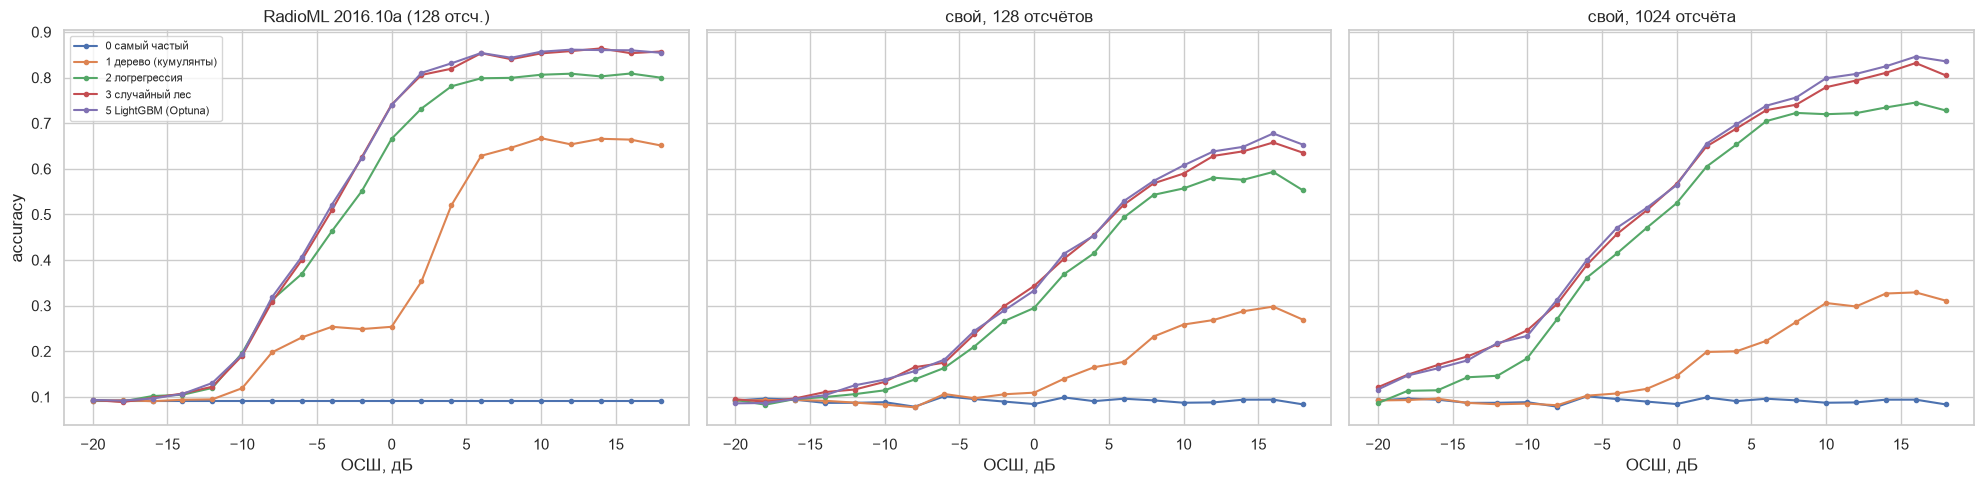

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
for ax, name in zip(axes, ["rml2016a", "synth_v1_128", "synth_v1"]):
    te = DS[name][DS[name].split == "test"]
    for (n, mname), p in preds.items():
        if n == name:
            acc_by_snr(te["label"], p, te["snr_db"]).plot(ax=ax, marker="o", ms=3, label=mname)
    ax.set_title({"rml2016a": "RadioML 2016.10a (128 отсч.)", "synth_v1_128": "свой, 128 отсчётов",
                  "synth_v1": "свой, 1024 отсчёта"}[name])
    ax.set_xlabel("ОСШ, дБ")
axes[0].set_ylabel("accuracy")
axes[0].legend(fontsize=8)
plt.tight_layout()
savefig("acc_vs_snr")
plt.show()

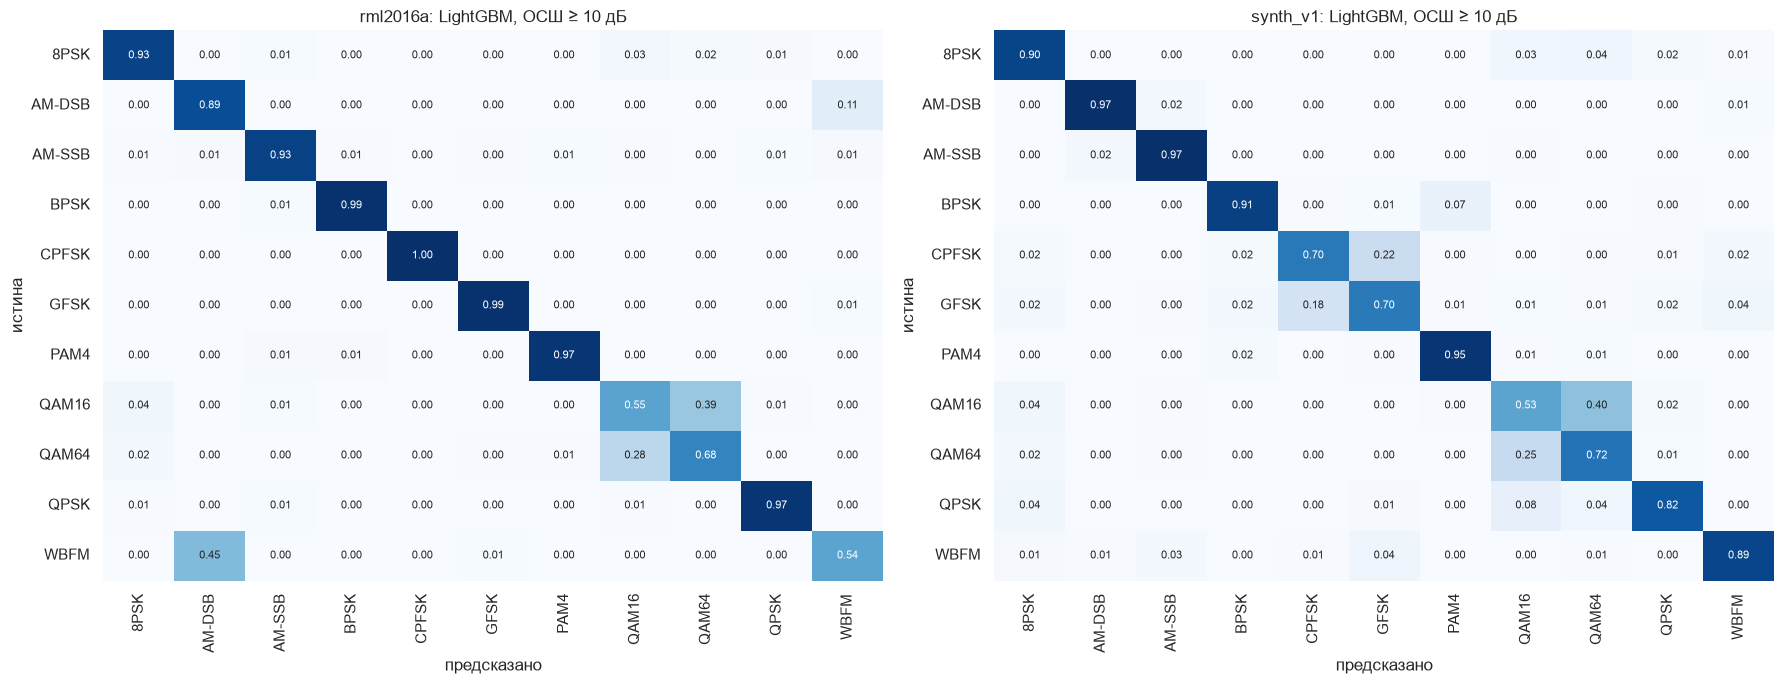

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, name in zip(axes, ["rml2016a", "synth_v1"]):
    te = DS[name][DS[name].split == "test"]
    m = te["snr_db"].to_numpy() >= 10
    cm = confusion_matrix(te["label"][m], preds[(name, "5 LightGBM (Optuna)")][m], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax,
                cbar=False, annot_kws={"size": 8})
    ax.set_title(f"{name}: LightGBM, ОСШ ≥ 10 дБ")
    ax.set_xlabel("предсказано")
    ax.set_ylabel("истина")
plt.tight_layout()
savefig("confusion_lgbm")
plt.show()

### Доверительные интервалы и критерий Мак-Немара
Бутстреп-ДИ 95 % для accuracy на тесте. **Критерий Мак-Немара** сравнивает две модели на одних и тех же
примерах (учитывает парность): значимо ли различаются доли ошибок LightGBM и логистической регрессии.

In [11]:
stat_rows = []
for name in ["rml2016a", "synth_v1"]:
    te = DS[name][DS[name].split == "test"]
    y = te["label"].to_numpy()
    a = preds[(name, "5 LightGBM (Optuna)")] == y
    b = preds[(name, "2 логрегрессия")] == y
    tbl = [[np.sum(a & b), np.sum(a & ~b)], [np.sum(~a & b), np.sum(~a & ~b)]]
    mc = mcnemar(tbl, exact=False, correction=True)
    lo, hi = bootstrap_ci(a)
    stat_rows.append({"датасет": name, "acc LightGBM": a.mean(), "ДИ 95 %": f"[{lo:.4f}; {hi:.4f}]",
                      "acc логрегрессия": b.mean(), "LGBM верно / ЛР нет": tbl[0][1],
                      "ЛР верно / LGBM нет": tbl[1][0], "p Мак-Немар": mc.pvalue})
pd.DataFrame(stat_rows).set_index("датасет")

,acc LightGBM,ДИ 95 %,acc логрегрессия,LGBM верно / ЛР нет,ЛР верно / LGBM нет,p Мак-Немар
датасет,,,,,,
rml2016a,0.547727,[0.5430; 0.5524],0.510295,4008,2361,1.636908e-94
synth_v1,0.514478,[0.5097; 0.5192],0.458703,5752,3298,1.294133e-146


## 7. Интерпретация: SHAP
Вклад признаков в решения LightGBM (среднее |SHAP| по классам и примерам, 3000 тестовых примеров).

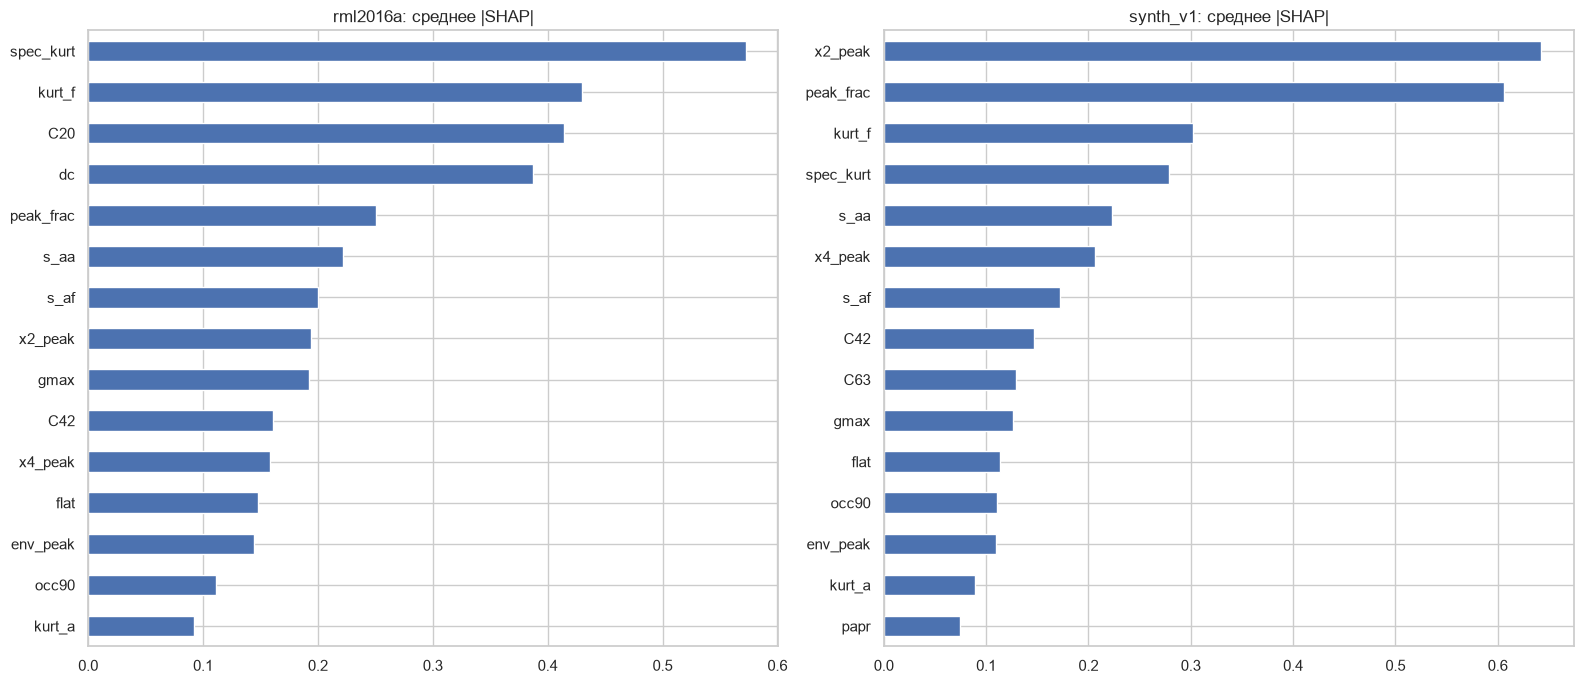

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, name in zip(axes, ["rml2016a", "synth_v1"]):
    d = DS[name]
    fs_best = max(["все", "отобранные"], key=lambda k: tuned[(name, k)][1])
    feats = FEATURES if fs_best == "все" else selected
    booster = lgb.Booster(model_str=(OUT / f"{name}_lgbm.txt").read_text(encoding="utf-8"))
    sample = d[d.split == "test"].sample(3000, random_state=SEED)[feats]
    sv = np.asarray(shap.TreeExplainer(booster).shap_values(sample))
    imp = pd.Series(np.abs(sv).mean(axis=tuple(i for i in range(sv.ndim) if sv.shape[i] != len(feats))),
                    index=feats).sort_values()
    imp.tail(15).plot.barh(ax=ax)
    ax.set_title(f"{name}: среднее |SHAP|")
plt.tight_layout()
savefig("shap")
plt.show()

## 8. Выводы

**Признаки.** Все 26 признаков ведут себя по теории (автотесты `tests/test_features.py`: C42 = −2 / −1 / −0,68 / −0,62
для BPSK / QPSK / QAM16 / QAM64, линия z⁴ у QPSK и её отсутствие у 8PSK, инвариантность к фазе).

**Статистический анализ и решения, принятые по нему:**
1. Критерий Краскела–Уоллиса: все признаки различают классы (p < 0,01), размер эффекта ε² в RadioML 0,05–0,85,
   в своём датасете 0,00–0,65 (условия шире — признаки «размыты»). По правилу ε² ≥ 0,08 и |ρ| ≤ 0,95 отобран 21 признак.
2. **Проверка отбора на val показала, что он вредит:** LightGBM на всех признаках лучше, чем на отобранных
   (RadioML 0,539 против 0,531; свой 0,501 против 0,492). Причина — одномерный размер эффекта не учитывает
   взаимодействия признаков: исключённый как «дубль» `spec_kurt` по SHAP оказался самым важным признаком в RadioML.
   **Решение: в моделях используются все признаки**; отбор по ε² оставлен как анализ, а не как фильтр.
3. Признак `spec_skew` в своём датасете имеет ε² ≈ 0, хотя должен выделять AM-SSB: знак асимметрии зависит от
   боковой полосы (USB/LSB — случайно), и в среднем эффект гасится. **Решение: для следующей версии признаков
   брать модуль асимметрии.**
4. Критерий Данна (поправка Холма) по трудным парам: QPSK/8PSK уверенно разделяются линией z⁴ и |C40|
   (эффект 0,95–0,99); AM-DSB/WBFM в своём датасете — линиями z²/z⁴ (0,99), а в RadioML только C20 и
   разбросом фазы (0,7) — подтверждает дефект RadioML (обе модуляции там — почти чистая несущая);
   **QAM16/QAM64 различаются лишь слабо** (пик-фактор, C42, эксцесс огибающей: эффект 0,2–0,36) — это
   главная ожидаемая ошибка.

**Baseline (тест):**

| модель | RadioML: acc / ОСШ ≥ 0 | свой 1024: acc / ОСШ ≥ 0 | свой 128: acc / ОСШ ≥ 0 |
|---|---|---|---|
| самый частый класс | 9,1 % / 9,1 % | 9,1 % / 9,1 % | 9,1 % / 9,1 % |
| дерево по кумулянтам | 36,1 % / 57,0 % | 17,8 % / 26,0 % | 15,7 % / 22,1 % |
| логистическая регрессия | 51,0 % / 78,0 % | 45,9 % / 68,6 % | 31,8 % / 49,8 % |
| случайный лес | 54,5 % / 83,5 % | 50,8 % / 74,0 % | 34,8 % / 54,4 % |
| **LightGBM (Optuna)** | **54,8 % / 83,7 %** | **51,4 % / 75,3 %** | **35,2 % / 55,3 %** |

- LightGBM значимо лучше логистической регрессии (Мак-Немар: p ≈ 10⁻⁹⁴ и 10⁻¹⁴⁶), 95 % ДИ accuracy на RadioML —
  [54,3; 55,2] %. Случайный лес почти не уступает бустингу — потолок задаёт информативность признаков, а не модель.
- «Экспертные правила» по одним кумулянтам слабы, особенно в своём датасете (18 %): кумулянты чувствительны к
  формированию спектра, сдвигу частоты и многолучёвости, которых в учебных постановках нет.
- **Длина окна критична для признаков:** на своём датасете 128 отсчётов → 35 %, 1024 → 51 %: статистики высших
  порядков по 128 отсчётам оцениваются с большим разбросом.
- Остаточные ошибки (ОСШ ≥ 10 дБ): QAM16↔QAM64 (до 40 %), в RadioML AM-DSB↔WBFM (45 % — дефект данных),
  в своём датасете CPFSK↔GFSK (≈ 20 %: при BT 0,5 и большом h формы почти совпадают).

**Итог этапа:** baseline на признаках — **54,8 % (RadioML) / 51,4 % (свой датасет)**; нейросети должны
его превзойти статистически значимо (этапы 4–5). Предварительно: CNN-LSTM на RadioML — 62,0 % (≥ 0 дБ — 91,7 %),
то есть на 7 п.п. выше; а эталонная VT-CNN2 из статьи 2016 г. (50,6 %) **хуже бустинга на признаках** —
простая CNN без аугментаций и нормировки не превосходит хорошую экспертную разработку признаков.